## Ordinary Least Squares Regression

### Learning Goals
* Understand the Ordinary Least Squares (OLS) objective of minimizing squared residual errors.
* Fit an OLS regression model in Python using `statsmodels`.
* Interpret regression parameters, standard errors, and model fit in the presence of noise.

---

### 1. The OLS Objective

Ordinary least squares estimates coefficients by minimizing the sum of squared vertical residuals between observed data and the fitted regression line:
$$
\min_{\beta_0, \beta_1} \sum_{i=1}^{n} (y_i - \beta_0 - \beta_1 x_i)^2
$$
A residual represents the observed outcome minus the model's fitted prediction ($e_i = y_i - \hat{y}_i$).

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.915
Model:                            OLS   Adj. R-squared:                  0.914
Method:                 Least Squares   F-statistic:                     1049.
Date:                Tue, 27 Oct 2026   Prob (F-statistic):           3.79e-54
Time:                        20:05:35   Log-Likelihood:                -192.42
No. Observations:                 100   AIC:                             388.8
Df Residuals:                      98   BIC:                             394.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          3.3131      0.332      9.969      0.0

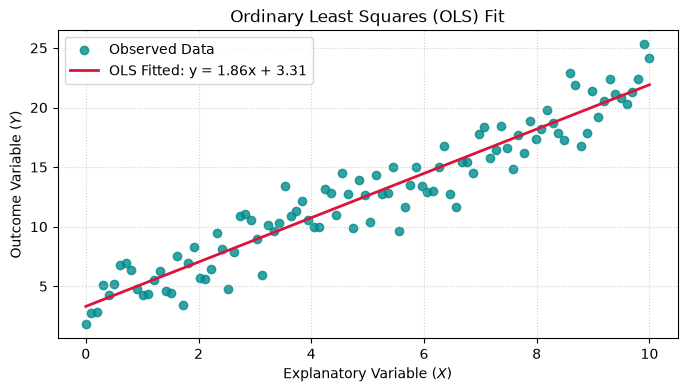

In [1]:
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

rng = np.random.default_rng(10)
x = np.linspace(0, 10, 100)
y = 4 + 1.8 * x + rng.normal(0, 2, size=len(x))

# Add constant for OLS intercept estimation
X = sm.add_constant(x)
result = sm.OLS(y, X).fit()

print(result.summary())

fitted = result.predict(X)

plt.figure(figsize=(8, 4))
plt.scatter(x, y, color='darkcyan', alpha=0.8, label="Observed Data")
plt.plot(x, fitted, color='crimson', linewidth=2, label=f"OLS Fitted: y = {result.params[1]:.2f}x + {result.params[0]:.2f}")
plt.xlabel("Explanatory Variable ($X$)")
plt.ylabel("Outcome Variable ($Y$)")
plt.title("Ordinary Least Squares (OLS) Fit")
plt.legend()
plt.grid(linestyle=':', alpha=0.6)
plt.show()

### Interpretation and Limitations

The OLS slope estimates the change in the conditional mean of $Y$ associated with a one-unit increase in $X$, assuming a linear specification. A true causal interpretation requires rigorous identification assumptions (e.g., exogeneity where $\mathbb{E}[\epsilon \mid X] = 0$).

---

### Exercises

Try each problem before running the verification code below:

1. Compare the estimated OLS coefficients with the true data-generating parameters ($\beta_0 = 4, \beta_1 = 1.8$).
2. Increase the noise standard deviation from $2$ to $8$ in the data generation step and re-run.
3. Observe and explain what happens to the uncertainty (standard errors) and confidence intervals of the coefficient estimates when noise increases.

In [2]:
# --- Exercise Verification & Explanations ---
print("=== Exercise Solutions & Checks ===")

print(f"\n1. Coefficient Comparison:")
print(f"   - True Parameters: Intercept = 4.0, Slope = 1.8")
print(f"   - OLS Estimates:   Intercept = {result.params[0]:.4f}, Slope = {result.params[1]:.4f}")

# Exercise 2 & 3: High noise simulation check
rng_noisy = np.random.default_rng(10)
y_noisy = 4 + 1.8 * x + rng_noisy.normal(0, 8, size=len(x))
result_noisy = sm.OLS(y_noisy, X).fit()

print(f"\n2 & 3. Impact of Higher Noise (SD = 8):")
print(f"   - OLS Estimates (Noisy): Intercept = {result_noisy.params[0]:.4f}, Slope = {result_noisy.params[1]:.4f}")
print(f"   - Standard Error of Slope (Low Noise):   {result.bse[1]:.4f}")
print(f"   - Standard Error of Slope (High Noise):  {result_noisy.bse[1]:.4f}")
print("   - Conclusion: Higher noise increases standard errors, widening confidence intervals")
print("     and increasing estimation uncertainty without biasing the coefficient point estimate.")

=== Exercise Solutions & Checks ===

1. Coefficient Comparison:
   - True Parameters: Intercept = 4.0, Slope = 1.8
   - OLS Estimates:   Intercept = 3.3131, Slope = 1.8596

2 & 3. Impact of Higher Noise (SD = 8):
   - OLS Estimates (Noisy): Intercept = 1.2526, Slope = 2.0386
   - Standard Error of Slope (Low Noise):   0.0574
   - Standard Error of Slope (High Noise):  0.2297
   - Conclusion: Higher noise increases standard errors, widening confidence intervals
     and increasing estimation uncertainty without biasing the coefficient point estimate.
